# Tutorial 1: Cu | Ni with EMT, analysis notebook

This notebook runs the workflow of `input.toml` (the same as `./run.sh`; a few seconds with ASE's EMT potential) and
analyses the results: the surface screening, the lateral registry and separation scans, the interface structure and
the work of adhesion and interface energy.

## 1. Run INTERFACER

`main()` takes the same options as the `interfacer` command; more options can be added after the input file, e.g.
`["--input", "input.toml", "-thor"]` to switch off the lateral scan. The output is written to `OUTPUT/` and
`interfaces.out`.

In [1]:
import warnings

from interfacer.cli import main

warnings.filterwarnings("ignore", message="Occupancies")   # harmless note of ASE's CIF reader
_ = main(["--input", "input.toml", "-q"])   # -q: warnings only (remove it to see the full log)

## 2. Results (`OUTPUT/results.json`)

In [2]:
import json

import matplotlib.pyplot as plt
import numpy as np
from ase.io import read
from ase.visualize.plot import plot_atoms

J = 0.160217663   # eV/nm^2 -> J/m^2
res = json.load(open("OUTPUT/results.json"))
print("Bulk energies: %.4f and %.4f eV/atom" % (res["E_bulk1"], res["E_bulk2"]))
print("Surfaces:", res["miller1"], "|", res["miller2"])
for n in (1, 2):
    for s in res["slabs%d" % n]:
        print("  slab %d %-12s %3d atoms  SFE = %6.2f eV/nm^2 = %.2f J/m^2" % (n, s["name"], s["natoms"], s["sfe"], s["sfe"] * J))
for r in res["interfaces"]:
    print("\nInterface %s (%s | %s)" % (r["name"], r["slab1"], r["slab2"]))
    print("  misfit %.2f%% -> %.2f%% after alignment, area %.1f A^2" % (100 * r["misfit_before"], 100 * r["misfit_after"], r["area"]))
    print("  W_surf = %.2f and %.2f J/m^2, separation %.2f A, %d interface(s) in the cell"
          % (r["W_surf1"] * J, r["W_surf2"] * J, r["sep"], r["n_interfaces"]))
    print("  W_ad = %.2f J/m^2, gamma_int = %.2f J/m^2" % (r["W_ad"] * J, r["gamma_int"] * J))

Bulk energies: -0.0070 and -0.0133 eV/atom
Surfaces: [1, 1, 1] | [1, 1, 1]
  slab 1 slab1_cut0    12 atoms  SFE =   6.52 eV/nm^2 = 1.04 J/m^2
  slab 2 slab2_cut0    12 atoms  SFE =  10.64 eV/nm^2 = 1.70 J/m^2

Interface interface_cuts_0_0 (slab1_cut0 | slab2_cut0)
  misfit 2.91% -> 2.91% after alignment, area 21.7 A^2
  W_surf = 1.04 and 1.70 J/m^2, separation 2.00 A, 2 interface(s) in the cell
  W_ad = 2.63 J/m^2, gamma_int = 0.12 J/m^2


## 3. Surface screening (`tsur`)

The surface energies of the (100), (110) and (111) slabs are in `interfaces.out`; fcc metals follow
(111) < (100) < (110).

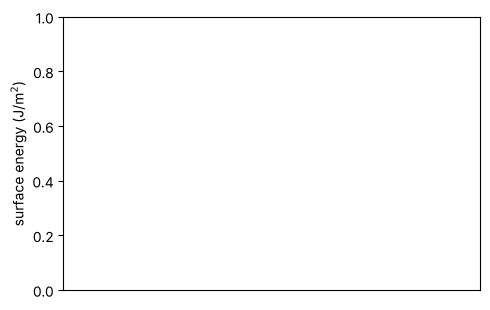

In [3]:
import re

text = open("interfaces.out").read()
rows = re.findall(r"W_surf\s+\((\w+)_(\d{3})\):\s+([\d.]+) eV/nm\^2", text)
fig, ax = plt.subplots(figsize=(5, 3.2))
for i, (el, hkl, w) in enumerate(rows):
    ax.bar(i, float(w) * J, color="C0" if el == "Cu" else "C1")
ax.set_xticks(range(len(rows)), ["%s(%s)" % (el, hkl) for el, hkl, _ in rows])
ax.set_ylabel("surface energy (J/m$^2$)")
plt.tight_layout()

## 4. Lateral registry scan (`thor`) and separation scan (`tsep`)

The bottom slab is shifted on a grid of fractions of the in-plane cell vectors with rigid slabs (single points); the
separation is then scanned at the best registry.

best shift: x = 0.25, y = 0.50


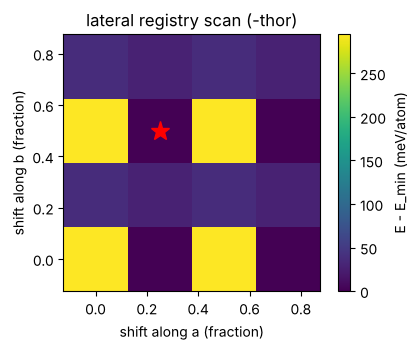

In [4]:
d = np.loadtxt("OUTPUT/conv_htrans.csv", delimiter=",", skiprows=1)
xs, ys = np.unique(d[:, 0]), np.unique(d[:, 1])
E = d[:, 2].reshape(len(xs), len(ys))
plt.figure(figsize=(4.5, 3.6))
dx, dy = xs[1] - xs[0], ys[1] - ys[0]   # each cell is centred on its sampled shift
plt.imshow((E.T - E.min()) * 1000, origin="lower", cmap="viridis",
           extent=[xs[0] - dx / 2, xs[-1] + dx / 2, ys[0] - dy / 2, ys[-1] + dy / 2])
plt.colorbar(label="E - E_min (meV/atom)")
i, j = np.unravel_index(np.argmin(E), E.shape)
plt.plot(xs[i], ys[j], "r*", ms=14)
plt.xlabel("shift along a (fraction)")
plt.ylabel("shift along b (fraction)")
plt.title("lateral registry scan (-thor)")
plt.tight_layout()
print("best shift: x = %.2f, y = %.2f" % (xs[i], ys[j]))

best separation: 2.00 A


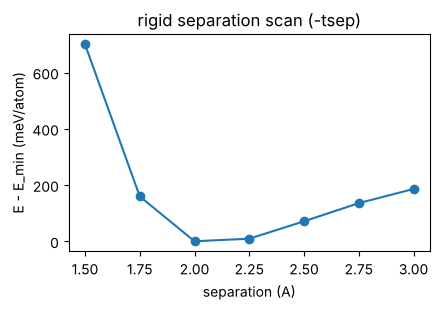

In [5]:
d = np.loadtxt("OUTPUT/conv_sep.csv", delimiter=",", skiprows=1)
plt.figure(figsize=(4.5, 3.2))
plt.plot(d[:, 0], (d[:, 1] - d[:, 1].min()) * 1000, "o-")
plt.xlabel("separation (A)")
plt.ylabel("E - E_min (meV/atom)")
plt.title("rigid separation scan (-tsep)")
plt.tight_layout()
print("best separation: %.2f A" % d[np.argmin(d[:, 1]), 0])

## 5. The interface structure

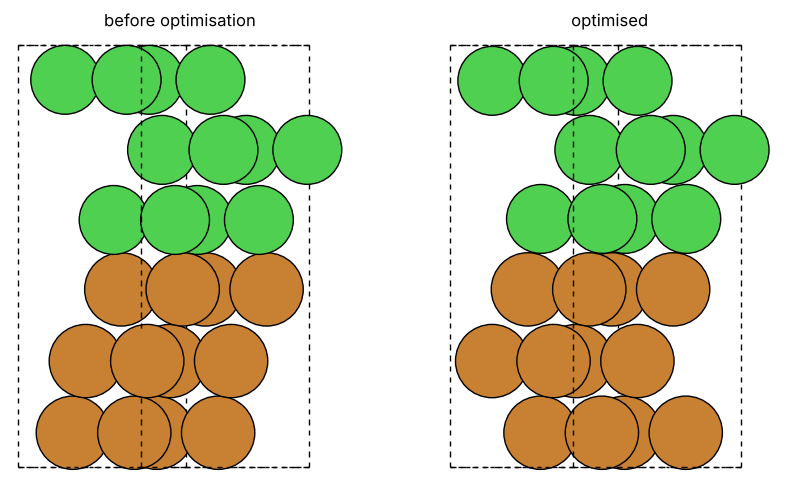

In [6]:
def show(path, ax, title, rotation="-90x"):
    atoms = read(path)
    plot_atoms(atoms, ax, rotation=rotation, radii=0.8)
    ax.set_title(title)
    ax.set_axis_off()

name = res["interfaces"][0]["name"]
fig, axes = plt.subplots(1, 2, figsize=(9, 5))
show("OUTPUT/%s.xyz" % name.replace("interface_cuts", "interface-pre_opt_cuts"), axes[0], "before optimisation")
show("OUTPUT/%s_opted.xyz" % name, axes[1], "optimised")
plt.tight_layout()

## 6. Consistency checks

For a coherent interface the work of adhesion cannot exceed the sum of the surface energies (it would give a negative
interface energy, Dupré relation $\gamma_{int} = \gamma_1 + \gamma_2 - W_{ad}$). Two similar fcc metals give a
small interface energy.

In [7]:
r = res["interfaces"][0]
g1, g2, wad = r["W_surf1"] * J, r["W_surf2"] * J, r["W_ad"] * J
print("gamma_Cu + gamma_Ni = %.2f J/m^2, W_ad = %.2f J/m^2, gamma_int = %.2f J/m^2" % (g1 + g2, wad, g1 + g2 - wad))
assert 0 < wad <= g1 + g2 + 0.05

gamma_Cu + gamma_Ni = 2.75 J/m^2, W_ad = 2.63 J/m^2, gamma_int = 0.12 J/m^2


## Things to try

* `main(["--input", "input.toml", "-vac_int", "8"])`: one interface and two free surfaces in the cell instead of two
  interfaces; W_ad should hardly change.
* `main(["--input", "input.toml", "-topt"])`: refine the registry and separation with a scipy optimisation.
* Tutorial 6 builds grain boundaries and three-layer interfaces with the same potential.